In [ ]:
import os
import numpy as np
import pandas as pd
import datetime as dt
import matplotlib.pyplot as plt
import importlib.util
from pathlib import Path

# --------------------
# Paths
# --------------------
BASE_DIR = Path(r"D:\tailieu")
BT_PATH = BASE_DIR / "bt.py"
DATA_1M_PATH = BASE_DIR / "VN30F1M.csv"  #vn30f1m
EXP_PATH = BASE_DIR / "expiration_date.csv"

# --------------------
# Load bt.py as module "bt"
# --------------------
spec = importlib.util.spec_from_file_location("bt", str(BT_PATH))
bt = importlib.util.module_from_spec(spec)
spec.loader.exec_module(bt)

# --------------------
# Strategy params (KEEP EXACT)
# --------------------
params = dict(
    # ---- LONG
    lookback_L=40, ma_fast_L=2, ma_slow_L=8,
    width_lookback_L=10, width_thr_L=0.003,
    atr_n_L=10, k_atr_L=0.05,
    buffer_pct_L=0.0005,
    slope_lb_L=15, slope_thr_L=0.15,

    # ---- SHORT
    lookback_S=40, ma_fast_S=2, ma_slow_S=6,
    width_lookback_S=20, width_thr_S=0.01,
    atr_n_S=10, k_atr_S=0.02,
    buffer_pct_S=0.0001,
    slope_lb_S=15, slope_thr_S=0.06,
)

tp_long  = 0.01
sl_long  = 0.01
tp_short = 0.008
sl_short = 0.008

FEE_POINTS_ROUNDTRIP = 0.8  # dùng đúng kiểu bt.py (fee/2 mỗi lần đổi vị thế)


In [ ]:
df1 = pd.read_csv(DATA_1M_PATH)

# chuẩn hoá tên cột (nếu file bạn đã đúng thì block này không đổi gì)
rename_map = {c: c.strip() for c in df1.columns}
df1 = df1.rename(columns=rename_map)

required = ["Date", "Open", "High", "Low", "Close", "Volume"]
missing = [c for c in required if c not in df1.columns]
if missing:
    raise ValueError(f"data1mins.csv thiếu cột: {missing}. Cần tối thiểu {required}")

# Date -> datetime
df1["Date"] = pd.to_datetime(df1["Date"])

# sort
df1 = df1.sort_values("Date").reset_index(drop=True)

df1.head()


,Date,Open,Close,High,Low,Volume
0,2017-08-10 09:16:00,757.9,757.9,757.9,757.9,6
1,2017-08-10 09:19:00,757.0,757.0,757.0,757.0,4
2,2017-08-10 09:22:00,756.8,756.8,756.8,756.8,5
3,2017-08-10 09:25:00,756.2,756.2,756.2,756.2,6
4,2017-08-10 09:28:00,755.5,755.5,755.5,755.5,5


In [ ]:
df15 = bt.resample(df1.copy(), sample_duration=15, type_data="Min")

# df15 có cột Date (datetime), Open/High/Low/Close/Volume
df15["Date"] = pd.to_datetime(df15["Date"])
df15 = df15.sort_values("Date").reset_index(drop=True)

# set index để làm indicator dễ
df15 = df15.set_index("Date")

# lọc giai đoạn backtest
start = pd.Timestamp("2020-01-01")
end   = pd.Timestamp("2025-02-02")  # loại ngày này
df15 = df15.loc[(df15.index >= start) & (df15.index < end)].copy()

df15.head(), df15.tail()


(                      Open   High    Low  Close  Volume
 Date                                                   
 2020-01-02 09:00:00  877.5  877.7  877.1  877.6    2216
 2020-01-02 09:15:00  877.6  878.5  876.6  878.5    3470
 2020-01-02 09:30:00  878.5  879.0  877.9  878.8    3523
 2020-01-02 09:45:00  878.9  879.5  878.5  878.6    4098
 2020-01-02 10:00:00  878.7  879.0  877.9  878.0    2870,
                        Open    High     Low   Close  Volume
 Date                                                       
 2025-01-24 13:45:00  1345.2  1346.4  1343.0  1343.3   14384
 2025-01-24 14:00:00  1343.1  1344.6  1342.5  1344.4    9762
 2025-01-24 14:15:00  1344.2  1345.9  1341.6  1341.8   19791
 2025-01-24 14:30:00  1342.1  1342.1  1342.1  1342.1      72
 2025-01-24 14:45:00  1343.9  1343.9  1343.9  1343.9    7852)

In [ ]:
exp = pd.read_csv(EXP_PATH)

# tìm cột ngày hợp lý (linh hoạt)
date_col = None
for c in exp.columns:
    if "date" in c.lower() or "exp" in c.lower() or "day" in c.lower():
        date_col = c
        break
if date_col is None:
    # fallback: lấy cột đầu tiên
    date_col = exp.columns[0]

exp_dates = pd.to_datetime(exp[date_col]).dt.date
exp_set = set(exp_dates.dropna().tolist())

len(exp_set), sorted(list(exp_set))[:5]


(2916,
 [datetime.date(2017, 1, 19),
  datetime.date(2017, 2, 16),
  datetime.date(2017, 3, 16),
  datetime.date(2017, 4, 20),
  datetime.date(2017, 5, 18)])

In [ ]:
bars = df15.copy()

H = bars["High"]
L = bars["Low"]
C = bars["Close"]

# -------- ATR helper
prevC = C.shift(1)
tr = pd.concat([
    (H - L).abs(),
    (H - prevC).abs(),
    (L - prevC).abs()
], axis=1).max(axis=1)

# -------- LONG indicators
upper_L = H.rolling(params["lookback_L"]).max().shift(1)

ma_fast_L = C.rolling(params["ma_fast_L"]).mean()
ma_slow_L = C.rolling(params["ma_slow_L"]).mean()

w_hi_L = H.rolling(params["width_lookback_L"]).max().shift(1)
w_lo_L = L.rolling(params["width_lookback_L"]).min().shift(1)
width_L = (w_hi_L - w_lo_L) / C

atr_L = tr.rolling(params["atr_n_L"]).mean()
buf_L = C * params["buffer_pct_L"] + atr_L * params["k_atr_L"]

slope_L = ma_slow_L.diff(params["slope_lb_L"]) / params["slope_lb_L"]

cond_long = (
    (C > (upper_L + buf_L)) &
    (ma_fast_L > ma_slow_L) &
    (width_L >= params["width_thr_L"]) &
    (slope_L > params["slope_thr_L"])
)

# -------- SHORT indicators
lower_S = L.rolling(params["lookback_S"]).min().shift(1)

ma_fast_S = C.rolling(params["ma_fast_S"]).mean()
ma_slow_S = C.rolling(params["ma_slow_S"]).mean()

w_hi_S = H.rolling(params["width_lookback_S"]).max().shift(1)
w_lo_S = L.rolling(params["width_lookback_S"]).min().shift(1)
width_S = (w_hi_S - w_lo_S) / C

atr_S = tr.rolling(params["atr_n_S"]).mean()
buf_S = C * params["buffer_pct_S"] + atr_S * params["k_atr_S"]

slope_S = ma_slow_S.diff(params["slope_lb_S"]) / params["slope_lb_S"]

cond_short = (
    (C < (lower_S - buf_S)) &
    (ma_fast_S < ma_slow_S) &
    (width_S >= params["width_thr_S"]) &
    (slope_S < (-params["slope_thr_S"]))
)

# clean NaN -> False
cond_long = cond_long.fillna(False)
cond_short = cond_short.fillna(False)

bars["sig_long"] = cond_long
bars["sig_short"] = cond_short

bars[["Open","High","Low","Close","sig_long","sig_short"]].tail(20)


,Open,High,Low,Close,sig_long,sig_short
Date,,,,,,
2025-01-23 14:45:00,1339.0,1339.0,1339.0,1339.0,False,False
2025-01-24 09:00:00,1340.1,1340.5,1337.6,1337.9,False,False
2025-01-24 09:15:00,1337.9,1341.4,1337.5,1340.2,False,False
2025-01-24 09:30:00,1340.2,1342.6,1340.1,1341.8,False,False
2025-01-24 09:45:00,1341.6,1341.8,1340.5,1341.3,False,False
2025-01-24 10:00:00,1341.0,1341.8,1337.8,1338.2,False,False
2025-01-24 10:15:00,1338.3,1340.1,1338.0,1339.1,False,False
2025-01-24 10:30:00,1339.0,1340.2,1338.8,1340.2,False,False
2025-01-24 10:45:00,1340.2,1341.0,1339.6,1340.2,False,False


In [ ]:
import numpy as np
import pandas as pd
import datetime as dt
from typing import Iterable, Optional

def build_position_close_exit_reset_decay(
    bars: pd.DataFrame,          # index = DateTime, columns: High/Low/Close/sig_long/sig_short
    exp_set: set,                # set(date) của ngày đáo hạn
    tp_long_base: float, sl_long_base: float,
    tp_short_base: float, sl_short_base: float,
    decay: float = 0.8,          # mỗi lần RESET: tp/sl *= decay
    max_hold_bars: int | None = None,      # KHÔNG hold quá n bar (None = tắt)

    # NEW: list/set các time cần skip khi đang flat
    skip_entry_times: Optional[Iterable[dt.time]] = (dt.time(9, 15),),

    allow_reentry_same_bar: bool = False,  # có cho phép EXIT rồi ENTER lại ngay cùng bar không
):
    idx = bars.index
    n = len(bars)

    H = bars["High"].to_numpy(float)
    L = bars["Low"].to_numpy(float)
    C = bars["Close"].to_numpy(float)

    sigL = bars["sig_long"].to_numpy(bool)
    sigS = bars["sig_short"].to_numpy(bool)

    # chuẩn hoá skip list -> set để check nhanh
    skip_set = None
    if skip_entry_times is not None:
        skip_set = set(skip_entry_times)

    pos = 0
    entry_price = np.nan
    entry_time = None
    entry_i = None

    tp_cur = None
    sl_cur = None

    pos_end = np.zeros(n, dtype=int)
    logs = []

    for i in range(n):
        t = idx[i]
        d = t.date()
        c = float(C[i])
        h = float(H[i])
        l = float(L[i])

        is_last_bar_of_day = (i == n - 1) or (idx[i + 1].date() != d)

        support_long = bool(sigL[i] and (not sigS[i]))
        support_short = bool(sigS[i] and (not sigL[i]))

        exited_this_bar = False

        # =========================
        # EXIT / RESET
        # =========================
        if pos != 0:
            hit_tp = hit_sl = False
            reason = None

            if pos == 1:
                tp_level = entry_price * (1.0 + tp_cur)
                sl_level = entry_price * (1.0 - sl_cur)
                hit_sl = (l <= sl_level)
                hit_tp = (h >= tp_level)
                if hit_sl or hit_tp:
                    reason = "SL" if (hit_sl and hit_tp) or hit_sl else "TP"
                    if support_long:
                        tp_old, sl_old = float(tp_cur), float(sl_cur)
                        tp_cur = float(tp_cur) * decay
                        sl_cur = float(sl_cur) * decay
                        logs.append({
                            "time": t, "event": "RESET", "side": "LONG", "reason": reason,
                            "pos_before": 1, "pos": 1, "px": c,
                            "entry_old": float(entry_price), "entry_new": c,
                            "tp_old": tp_old, "sl_old": sl_old,
                            "tp_new": float(tp_cur), "sl_new": float(sl_cur),
                            "hold_bars": int(i - entry_i + 1) if entry_i is not None else None,
                        })
                        entry_price = c
                        entry_time = t
                        entry_i = i
                    else:
                        logs.append({
                            "time": t, "event": "EXIT", "side": "LONG", "reason": reason,
                            "pos_before": 1, "pos": 0, "px": c,
                            "entry": float(entry_price), "entry_time": entry_time,
                            "tp_used": float(tp_cur), "sl_used": float(sl_cur),
                            "hold_bars": int(i - entry_i + 1) if entry_i is not None else None,
                        })
                        pos = 0
                        entry_price = np.nan
                        entry_time = None
                        entry_i = None
                        tp_cur = sl_cur = None
                        exited_this_bar = True

            else:  # pos == -1
                tp_level = entry_price * (1.0 - tp_cur)
                sl_level = entry_price * (1.0 + sl_cur)
                hit_sl = (h >= sl_level)
                hit_tp = (l <= tp_level)
                if hit_sl or hit_tp:
                    reason = "SL" if (hit_sl and hit_tp) or hit_sl else "TP"
                    if support_short:
                        tp_old, sl_old = float(tp_cur), float(sl_cur)
                        tp_cur = float(tp_cur) * decay
                        sl_cur = float(sl_cur) * decay
                        logs.append({
                            "time": t, "event": "RESET", "side": "SHORT", "reason": reason,
                            "pos_before": -1, "pos": -1, "px": c,
                            "entry_old": float(entry_price), "entry_new": c,
                            "tp_old": tp_old, "sl_old": sl_old,
                            "tp_new": float(tp_cur), "sl_new": float(sl_cur),
                            "hold_bars": int(i - entry_i + 1) if entry_i is not None else None,
                        })
                        entry_price = c
                        entry_time = t
                        entry_i = i
                    else:
                        logs.append({
                            "time": t, "event": "EXIT", "side": "SHORT", "reason": reason,
                            "pos_before": -1, "pos": 0, "px": c,
                            "entry": float(entry_price), "entry_time": entry_time,
                            "tp_used": float(tp_cur), "sl_used": float(sl_cur),
                            "hold_bars": int(i - entry_i + 1) if entry_i is not None else None,
                        })
                        pos = 0
                        entry_price = np.nan
                        entry_time = None
                        entry_i = None
                        tp_cur = sl_cur = None
                        exited_this_bar = True

            # 2) EXPIRY close last bar
            if pos != 0 and (d in exp_set) and is_last_bar_of_day:
                logs.append({
                    "time": t, "event": "EXIT", "side": ("LONG" if pos == 1 else "SHORT"), "reason": "EXPIRY",
                    "pos_before": int(pos), "pos": 0, "px": c,
                    "entry": float(entry_price), "entry_time": entry_time,
                    "tp_used": float(tp_cur), "sl_used": float(sl_cur),
                    "hold_bars": int(i - entry_i + 1) if entry_i is not None else None,
                })
                pos = 0
                entry_price = np.nan
                entry_time = None
                entry_i = None
                tp_cur = sl_cur = None
                exited_this_bar = True

            # 3) MAX HOLD
            if pos != 0 and (max_hold_bars is not None) and (entry_i is not None):
                hold_bars = int(i - entry_i + 1)
                if hold_bars >= int(max_hold_bars):
                    logs.append({
                        "time": t, "event": "EXIT", "side": ("LONG" if pos == 1 else "SHORT"), "reason": "MAX_HOLD",
                        "pos_before": int(pos), "pos": 0, "px": c,
                        "entry": float(entry_price), "entry_time": entry_time,
                        "tp_used": float(tp_cur), "sl_used": float(sl_cur),
                        "hold_bars": hold_bars,
                    })
                    pos = 0
                    entry_price = np.nan
                    entry_time = None
                    entry_i = None
                    tp_cur = sl_cur = None
                    exited_this_bar = True

        # =========================
        # ENTRY (flat)
        # =========================
        if pos == 0:
            # chặn vào lệnh mới nếu time nằm trong skip list
            if (skip_set is not None) and (t.time() in skip_set):
                pass
            else:
                if (not allow_reentry_same_bar) and exited_this_bar:
                    pass
                else:
                    if support_long:
                        pos = 1
                        entry_price = c
                        entry_time = t
                        entry_i = i
                        tp_cur = float(tp_long_base)
                        sl_cur = float(sl_long_base)
                        logs.append({
                            "time": t, "event": "ENTER", "side": "LONG", "reason": "",
                            "pos_before": 0, "pos": 1, "px": c,
                            "tp_new": float(tp_cur), "sl_new": float(sl_cur),
                        })
                    elif support_short:
                        pos = -1
                        entry_price = c
                        entry_time = t
                        entry_i = i
                        tp_cur = float(tp_short_base)
                        sl_cur = float(sl_short_base)
                        logs.append({
                            "time": t, "event": "ENTER", "side": "SHORT", "reason": "",
                            "pos_before": 0, "pos": -1, "px": c,
                            "tp_new": float(tp_cur), "sl_new": float(sl_cur),
                        })

        pos_end[i] = pos

    pos_ser = pd.Series(pos_end, index=idx, name="Position").astype(int)
    log_df = pd.DataFrame(logs)
    return pos_ser, log_df
pos15, log_df = build_position_close_exit_reset_decay(
    bars=bars,
    exp_set=exp_set,
    tp_long_base=tp_long,  sl_long_base=sl_long,
    tp_short_base=tp_short, sl_short_base=sl_short,
    decay=0.95,
    max_hold_bars=100,
    skip_entry_times=[ dt.time(14,45), dt.time(14,30),dt.time(13,15)],
    allow_reentry_same_bar=True
)


Margin: 17.88
Margin after fee: 14.42
MDD: 101.9 (9.23%)
   Total trading quantity: 444
         Profit per trade: 3.34
             Total Profit: 1838.7
         Profit after fee: 1483.5
 Trading quantity per day: 0.35
Number of days of overnight holding: 45.0%
 Profit per day after fee: 1.18
          Return per year: 28.28%
          Profit per year: 296.46
                  HitRate: 55.41%
            Daily HitRate: 54.97%
          Weekly HitRate : 66.67%
         Monthly HitRate : 78.69%
                     Long: 213
                    Short: 231
             Hitrate long: 64.79%
            Hitrate short: 46.75%
Longest consecutive losing days: 8


D:\tailieu\bt.py:687: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  gain_monthly = df.gain.resample("1M").sum().dropna()


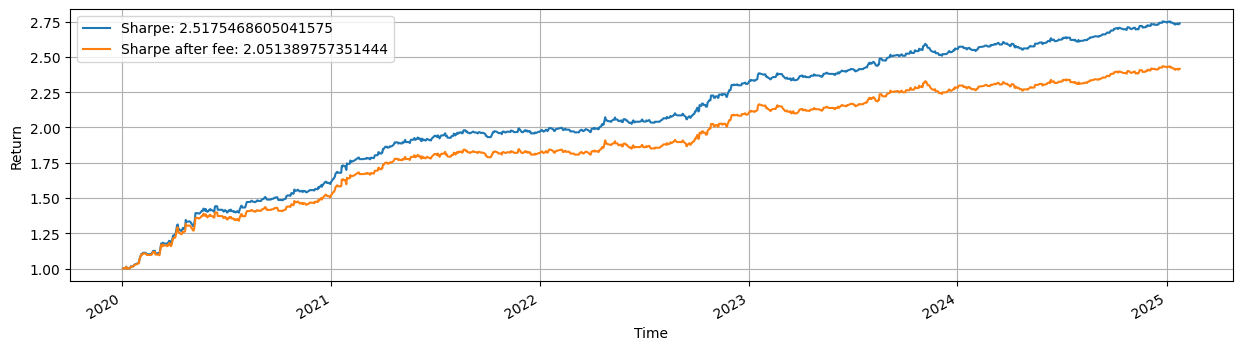

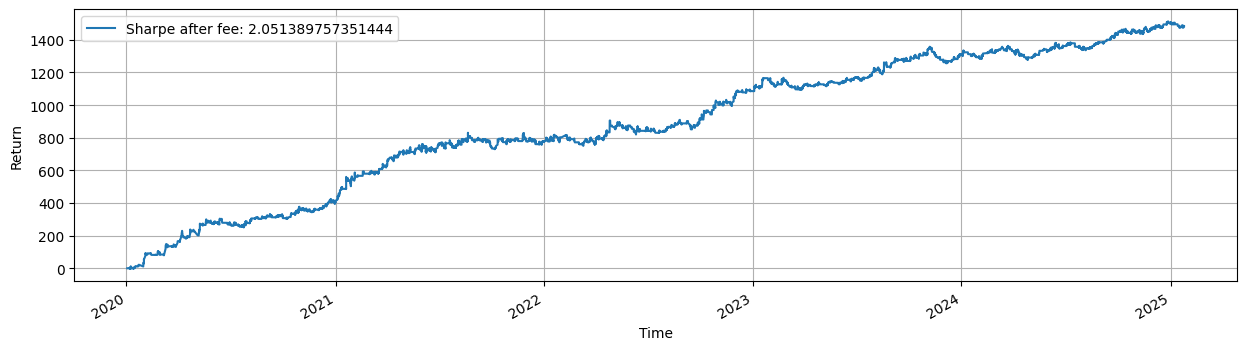

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=pd.errors.SettingWithCopyWarning)
warnings.filterwarnings("ignore", message=".*ChainedAssignmentError.*")

bt_df = pd.DataFrame({
    "Datetime": bars.index,
    "Close": bars["Close"].values,
    "Position": pos15.values
}).set_index("Datetime")

info = bt.BacktestInformation(
    Datetime=bt_df.index.to_series(),
    Position=bt_df["Position"],
    Close=bt_df["Close"],
    fee=FEE_POINTS_ROUNDTRIP
)

_ = info.Plot_PNL(plot=True)
